In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from collections import deque
import imageio
import heapq
from unicodedata import name

In [9]:
class CityDeliveryEnv:
    def __init__(self, grid_map, spawn_rate=0.05):
        # Сохраняем исходную карту
        self.base_map = grid_map.copy()
        self.height, self.width = grid_map.shape
        self.spawn_rate = spawn_rate
        # Находим координаты ключевых объектов:
        self.start_positions = list(zip(*np.where(self.base_map == 2)))
        
        self.spawn_positions = list(zip(*np.where(self.base_map == 3)))
        
        self.target_positions = list(zip(*np.where(self.base_map == 4)))
        
        # Карта чистого дорожного полотна 
        self.walkable_mask = (self.base_map != 1)
        
        self.actions = {
            0: (-1, 0),  
            1: (1, 0),  
            2: (0, -1), 
            3: (0, 1),   
            4: (0, 0)
        }
        
        # Текущие динамические переменные
        self.agent_pos = None
        self.vehicles = []

    def reset(self, start_idx):
        """Сброс состояния среды перед новым эпизодом."""

        self.agent_pos = self.start_positions[start_idx]    
        self.vehicles = []
        return self._get_observation()

    def step(self, action: int):
        """
        Моделирование одного шага агента в среде."""

        # Вычисляем предполагаемую новую позицию агента
        dr, dc = self.actions[action]
        curr_r, curr_c = self.agent_pos
        next_r, next_c = curr_r + dr, curr_c + dc
        
        # Проверяем, свободна ли ячейка (не стена и не машина)
        if 0 <= next_r < self.height and 0 <= next_c < self.width:
            if self.walkable_mask[next_r, next_c] and (next_r, next_c) not in [v["pos"] for v in self.vehicles]:
                self.agent_pos = (next_r, next_c)
        
        # Обновляем движение трафика
        self._update_vehicles()
        
        # Проверяем условия завершения эпизода и рассчитываем награду
        reward = -1  # Штраф за шаг (время)
        done = False
        info = {"status": "in_progress"}
        
        vehicles_positions = [v["pos"] for v in self.vehicles]
        
        # Авария (столкновение с машиной)
        if self.agent_pos in vehicles_positions:
            reward = -5
            done = True
            info["status"] = "crash"
            
        # Достижение цели
        elif self.base_map[self.agent_pos] == 4:
            reward = 100
            done = True
            info["status"] = "success"
            
        return self._get_observation(), reward, done, info

    def _get_observation(self):
        """Возвращает текущее состояние среды."""
        return {
            "agent_pos": self.agent_pos[0] * self.width + self.agent_pos[1],
            "vehicles_pos": [v["pos"] for v in self.vehicles]
        }
    
    def _update_vehicles(self):
        """Логика спавна и движения сторонних автомобилей."""
        spawn_prob = self.spawn_rate
        for spawn_pos in self.spawn_positions:
            # Проверяем, нет ли уже машины в этой точке
            occupied = any(v["pos"] == spawn_pos for v in self.vehicles)
            if not occupied and np.random.rand() < spawn_prob:
                lifetime = np.random.randint(15, 151)
                self.vehicles.append({
                    "pos": spawn_pos,
                    "last_dir": None,
                    "lifetime": lifetime
                })
        
        updated_vehicles = []
        
        # Перемещение существующих машин
        for vehicle in self.vehicles:
            vehicle["lifetime"] -= 1
            
            # Время жизни истекло
            if vehicle["lifetime"] <= 0:
                continue
                
            curr_r, curr_c = vehicle["pos"]
            
            # Находим все доступные соседние ячейки
            valid_moves = []
            for action_id, (dr, dc) in self.actions.items():
                if action_id == 4: # Исключаем остановку для машин
                    continue
                nr, nc = curr_r + dr, curr_c + dc
                if 0 <= nr < self.height and 0 <= nc < self.width:
                    if self.walkable_mask[nr, nc]:
                        valid_moves.append((action_id, (nr, nc)))
            
            # Если ехать некуда, машина остается на месте
            if not valid_moves:
                updated_vehicles.append(vehicle)
                continue
                
            last_dir = vehicle["last_dir"]
            chosen_move = None
            
            # Проверяем, доступно ли продолжение предыдущего направления
            same_dir_move = [m for m in valid_moves if m[0] == last_dir]
            
            if same_dir_move and np.random.rand() < 0.7:
                # 70% вероятность продолжить движение прямо
                chosen_move = same_dir_move[0]
            else:
                # Выбор случайного направления из доступных на развилке / из тупика
                rand_idx = np.random.choice(len(valid_moves))
                chosen_move = valid_moves[rand_idx]
                
            # Обновляем координаты и направление машины
            vehicle["last_dir"] = chosen_move[0]
            vehicle["pos"] = chosen_move[1]
            updated_vehicles.append(vehicle)
            
        self.vehicles = updated_vehicles
        
    def render(self):
      """Отрисовка текущего состояния среды в виде RGB-изображения."""
      fig, ax = plt.subplots(figsize=(6, 6), facecolor='#F8FAFC')

      # Создаем цветовую матрицу сетки
      grid_viz = np.zeros((self.height, self.width, 3))
      color_dict = {
          0: [1.0, 1.0, 1.0],  # Проезжая часть (белый)
          1: [0.2, 0.2, 0.2],  # Стены/препятствия (темно-серый)
          2: [0.5, 0.8, 1.0],  # Старт агента (голубой)
          3: [0.9, 0.6, 0.1],  # Спавн машин (оранжевый)
          4: [0.2, 0.8, 0.2],  # Целевая область (зеленый)
      }

      for r in range(self.height):
        for c in range(self.width):
          val = self.base_map[r, c]
          grid_viz[r, c] = color_dict.get(val, [1, 1, 1])

      ax.imshow(grid_viz, origin="upper")

      # Отрисовка агента
      if self.agent_pos:
        ax.scatter(
            self.agent_pos[1],
            self.agent_pos[0],
            color="blue",
            s=30,
            marker="s",
            label="Агент",
        )

      # Отрисовка других машин
      vehicle_positions = [v["pos"] for v in self.vehicles]
      if vehicle_positions:
        vr = [p[0] for p in vehicle_positions]
        vc = [p[1] for p in vehicle_positions]
        ax.scatter(vc, vr, color="red", s=30, marker="o", label="Машины")

      ax.set_xticks([])
      ax.set_yticks([])
      ax.set_title(
          f"Pos: {self.agent_pos} | Status: {len(self.vehicles)} cars"
      )

      fig.canvas.draw()
      image = np.asarray(fig.canvas.buffer_rgba())[:, :, :3]
      plt.close(fig)
      return image

In [10]:
class BFSPlanner:
    def __init__(self, env):
        self.env = env
        
    def get_action(self, agent_pos):
        """
        Находит кратчайший путь от текущей позиции агента до цели,
        учитывая статические стены и текущие позиции машин как препятствия.
        """
        targets = set(self.env.target_positions)
        
        if agent_pos in targets:
            return 4
            
        queue = deque([agent_pos])
        visited = {agent_pos}
        parent = {agent_pos: None}
        move_action = {agent_pos: None}
        
        # Фиксируем текущие позиции машин на момент планирования
        vehicle_positions = set(v["pos"] for v in self.env.vehicles)
        
        found_target = None
        
        while queue:
            current = queue.popleft()
            
            if current in targets:
                found_target = current
                break
                
            r, c = current
            for action_id, (dr, dc) in self.env.actions.items():
                if action_id == 4:
                    continue
                
                nr, nc = r + dr, c + dc
                next_pos = (nr, nc)
                
                # Проверяем границы, проходимость карты и отсутствие машины
                if 0 <= nr < self.env.height and 0 <= nc < self.env.width:
                    is_walkable = self.env.walkable_mask[nr, nc]
                    is_free_from_vehicle = next_pos not in vehicle_positions
                    
                    if is_walkable and is_free_from_vehicle and next_pos not in visited:
                        visited.add(next_pos)
                        parent[next_pos] = current
                        move_action[next_pos] = action_id
                        queue.append(next_pos)
                        
        if not found_target:
            return 4  # Если путь заблокирован, стоим на месте
            
        # Восстанавливаем первый шаг пути
        curr = found_target
        path_actions = []
        while parent[curr] is not None:
            path_actions.append(move_action[curr])
            curr = parent[curr]
            
        if not path_actions:
            return 4
            
        return path_actions[-1]

In [11]:
class CautiousPlanner:
    def __init__(self, env, safety_penalty=30):
        self.env = env
        self.safety_penalty = safety_penalty  # Штраф за приближение к машинам
        
    def get_action(self, agent_pos):
        """
        Строит путь методом Дейкстры, избегая не только сами машины, 
        но и зоны повышенного риска вблизи них (создает буфер безопасности).
        """
        targets = set(self.env.target_positions)
        
        if agent_pos in targets:
            return 4  # Стоп
            
        vehicle_positions = set(v["pos"] for v in self.env.vehicles)
        
        # Создаем зону безопасности вокруг машин
        dangerous_cells = set()
        for vr, vc in vehicle_positions:
            dangerous_cells.add((vr, vc))
            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                dangerous_cells.add((vr + dr, vc + dc))
                
        # Очередь с приоритетом для алгоритма Дейкстры:
        pq = [(0, agent_pos)]
        costs = {agent_pos: 0}
        parent = {agent_pos: None}
        move_action = {agent_pos: None}
        
        found_target = None
        
        while pq:
            current_cost, current = heapq.heappop(pq)
            
            if current in targets:
                found_target = current
                break
                
            if current_cost > costs.get(current, float('inf')):
                continue
                
            r, c = current
            for action_id, (dr, dc) in self.env.actions.items():
                if action_id == 4:
                    continue
                    
                nr, nc = r + dr, c + dc
                next_pos = (nr, nc)
                
                # Проверяем границы и статическую маску (не стена)
                if 0 <= nr < self.env.height and 0 <= nc < self.env.width:
                    if not self.env.walkable_mask[nr, nc]:
                        continue
                    # На саму машину наступать категорически нельзя
                    if next_pos in vehicle_positions:
                        continue
                        
                    # Базовая стоимость шага = 1. 
                    # Если рядом машина, добавляем штраф.
                    step_cost = 1
                    if next_pos in dangerous_cells:
                        step_cost += self.safety_penalty
                        
                    new_cost = current_cost + step_cost
                    
                    if next_pos not in costs or new_cost < costs[next_pos]:
                        costs[next_pos] = new_cost
                        parent[next_pos] = current
                        move_action[next_pos] = action_id
                        heapq.heappush(pq, (new_cost, next_pos))
                        
        if not found_target:
            return 4
            
        # Восстанавливаем первый шаг пути
        curr = found_target
        path_actions = []
        while parent[curr] is not None:
            path_actions.append(move_action[curr])
            curr = parent[curr]
            
        if not path_actions:
            return 4
            
        return path_actions[-1]

In [ ]:
class AggressivePlanner:
    def __init__(self, env):
        self.env = env
        
    def get_action(self, agent_pos):
        """
        Агрессивный планировщик: ведет агента по кратчайшей траектории к цели,
        полностью игнорируя движущийся трафик.
        Использует жадный поиск по расстоянию через манхэттенское расстояние до цели.
        """
        targets = set(self.env.target_positions)
        
        if agent_pos in targets:
            return 4  # Стоп
            
        # Выбираем ближайшую цель, если их несколько
        target = min(targets, key=lambda t: abs(t[0] - agent_pos[0]) + abs(t[1] - agent_pos[1]))
        
        pq = []
        # Эвристика: манхэттенское расстояние до цели
        h_init = abs(agent_pos[0] - target[0]) + abs(agent_pos[1] - target[1])
        heapq.heappush(pq, (h_init, agent_pos))
        
        visited = {agent_pos}
        parent = {agent_pos: None}
        move_action = {agent_pos: None}
        
        found_target = None
        
        while pq:
            _, current = heapq.heappop(pq)
            
            if current in targets:
                found_target = current
                break
                
            r, c = current
            for action_id, (dr, dc) in self.env.actions.items():
                if action_id == 4:
                    continue
                    
                nr, nc = r + dr, c + dc
                next_pos = (nr, nc)
                
                # Проверяем только стены, машины намеренно игнорируем!
                if 0 <= nr < self.env.height and 0 <= nc < self.env.width:
                    if self.env.walkable_mask[nr, nc] and next_pos not in visited:
                        visited.add(next_pos)
                        parent[next_pos] = current
                        move_action[next_pos] = action_id
                        
                        # Приоритет отдается клеткам, которые ближе к цели
                        h = abs(nr - target[0]) + abs(nc - target[1])
                        heapq.heappush(pq, (h, next_pos))
                        
        if not found_target:
            return 4
            
        # Восстанавливаем первый шаг пути
        curr = found_target
        path_actions = []
        while parent[curr] is not None:
            path_actions.append(move_action[curr])
            curr = parent[curr]
            
        if not path_actions:
            return 4
            
        return path_actions[-1]

In [13]:
with open('citymap.txt', 'r', encoding='utf-8') as f:
    lines = [list(line.strip()) for line in f if line.strip()]
results = {}

In [14]:
seeds = [42, 123, 999, 2024, 7]
results["BFS"] = {}
for prob in [0.02, 0.04, 0.06, 0.08, 0.10]:
    print(f"\n=== Тестирование при spawn_rate = {prob} ===")
    env = CityDeliveryEnv(np.array(lines, dtype='U1').astype(int), spawn_rate=prob)
    planner = BFSPlanner(env)
    results["BFS"][prob] = {}
    for seed in seeds:
        np.random.seed(seed)
        successes = 0
        crashes = 0
        steps_list = []
        for episode in range (100):
            start_idx = np.random.randint(len(env.start_positions))
            obs = env.reset(start_idx)
            # frames = []
            done = False
            step_count = 0
            
            while not done and step_count < 250:
                agent_pos = obs["agent_pos"]
                # Передаем координаты (row, col)
                action = planner.get_action((agent_pos // env.width, agent_pos % env.width))
                obs, reward, done, info = env.step(action)

                step_count += 1
                # frame = env.render()
                # frames.append(frame)

                if info["status"] == "crash":
                    print(f"Эпизод {episode}: Авария на шаге {step_count}.")
                    crashes += 1
                    break
                if info["status"] == "success":
                    print(f"Эпизод {episode}: Успех! Цель достигнута за {step_count} шагов.")
                    # filename = f"episode_BFS_{episode}.gif"
                    # imageio.mimsave(filename, frames, duration=0.1)
                    successes += 1
                    steps_list.append(step_count)
                    break      
        success_prob = (successes / 100) * 100
        avg_steps = np.mean(steps_list) if steps_list else 0
            
        results["BFS"][prob][seed] = {"success_prob": success_prob,
                "avg_steps": avg_steps,
                "steps_distribution": steps_list
            }
        print(f"[BFS] Успех: {results['BFS'][prob][seed]['success_prob']:.1f}% | Ср. шагов: {results['BFS'][prob][seed]['avg_steps']:.1f}")


=== Тестирование при spawn_rate = 0.02 ===
Эпизод 0: Успех! Цель достигнута за 93 шагов.
Эпизод 1: Авария на шаге 87.
Эпизод 2: Успех! Цель достигнута за 91 шагов.
Эпизод 3: Успех! Цель достигнута за 96 шагов.
Эпизод 4: Авария на шаге 66.
Эпизод 5: Успех! Цель достигнута за 97 шагов.
Эпизод 6: Успех! Цель достигнута за 90 шагов.
Эпизод 7: Авария на шаге 78.
Эпизод 8: Успех! Цель достигнута за 100 шагов.
Эпизод 9: Успех! Цель достигнута за 89 шагов.
Эпизод 10: Успех! Цель достигнута за 92 шагов.
Эпизод 11: Успех! Цель достигнута за 100 шагов.
Эпизод 12: Успех! Цель достигнута за 101 шагов.
Эпизод 13: Успех! Цель достигнута за 90 шагов.
Эпизод 14: Успех! Цель достигнута за 89 шагов.
Эпизод 15: Авария на шаге 63.
Эпизод 16: Успех! Цель достигнута за 98 шагов.
Эпизод 17: Авария на шаге 61.
Эпизод 18: Успех! Цель достигнута за 91 шагов.
Эпизод 19: Успех! Цель достигнута за 90 шагов.
Эпизод 20: Успех! Цель достигнута за 94 шагов.
Эпизод 21: Авария на шаге 52.
Эпизод 22: Авария на шаге 93.
Э

In [15]:
seeds = [42, 123, 999, 2024, 7]
results["Careful"] = {}
for prob in [0.02, 0.04, 0.06, 0.08, 0.10]:
    env = CityDeliveryEnv(np.array(lines, dtype='U1').astype(int), spawn_rate=prob)
    planner = CautiousPlanner(env, safety_penalty=40) 
    results["Careful"][prob] = {}
    for seed in seeds:
        np.random.seed(seed)
        steps_list = []
        successes = 0
        crashes = 0
        for episode in range(100):  
            start_idx = np.random.randint(len(env.start_positions))
            obs = env.reset(start_idx)
            # frames = []
            done = False
            step_count = 0
            
            while not done and step_count < 250:
                agent_pos = obs["agent_pos"]
                action = planner.get_action((agent_pos // env.width, agent_pos % env.width))
                obs, reward, done, info = env.step(action)

                step_count += 1
                # frame = env.render()
                # frames.append(frame)

                if info["status"] == "crash":
                    crashes += 1
                    print(f"Эпизод {episode}: Авария на шаге {step_count} (осторожность не помогла).")
                    break
                if info["status"] == "success":
                    successes += 1
                    steps_list.append(step_count)
                    print(f"Эпизод {episode}: Успех! Цель достигнута за {step_count} шагов.")
                    # filename = f"episode_Cautious_{episode}.gif"
                    # imageio.mimsave(filename, frames, duration=0.1)
                    break
        success_prob = (successes / 100) * 100
        avg_steps = np.mean(steps_list) if steps_list else 0
            
        results["Careful"][prob][seed] = {"success_prob": success_prob,
                "avg_steps": avg_steps,
                "steps_distribution": steps_list
            }
        print(f"[Careful] Успех: {results['Careful'][prob][seed]['success_prob']:.1f}% | Ср. шагов: {results['Careful'][prob][seed]['avg_steps']:.1f}")

Эпизод 0: Успех! Цель достигнута за 92 шагов.
Эпизод 1: Успех! Цель достигнута за 105 шагов.
Эпизод 2: Успех! Цель достигнута за 110 шагов.
Эпизод 3: Авария на шаге 83 (осторожность не помогла).
Эпизод 4: Успех! Цель достигнута за 106 шагов.
Эпизод 5: Авария на шаге 104 (осторожность не помогла).
Эпизод 6: Успех! Цель достигнута за 102 шагов.
Эпизод 7: Успех! Цель достигнута за 101 шагов.
Эпизод 8: Успех! Цель достигнута за 131 шагов.
Эпизод 9: Успех! Цель достигнута за 96 шагов.
Эпизод 10: Успех! Цель достигнута за 89 шагов.
Эпизод 11: Успех! Цель достигнута за 97 шагов.
Эпизод 12: Авария на шаге 36 (осторожность не помогла).
Эпизод 13: Успех! Цель достигнута за 111 шагов.
Эпизод 14: Успех! Цель достигнута за 97 шагов.
Эпизод 15: Успех! Цель достигнута за 91 шагов.
Эпизод 16: Успех! Цель достигнута за 128 шагов.
Эпизод 17: Успех! Цель достигнута за 147 шагов.
Эпизод 18: Успех! Цель достигнута за 89 шагов.
Эпизод 19: Успех! Цель достигнута за 156 шагов.
Эпизод 20: Авария на шаге 120 (о

In [16]:
seeds = [42, 123, 999, 2024, 7]
results["Aggressive"] = {}
planner = AggressivePlanner(env) 
for prob in [0.02, 0.04, 0.06, 0.08, 0.10]:
    print(f"\n=== Тестирование при spawn_rate = {prob} ===")
    env = CityDeliveryEnv(np.array(lines, dtype='U1').astype(int), spawn_rate=prob)
    planner = AggressivePlanner(env)
    results["Aggressive"][prob] = {}
    for seed in seeds:
        np.random.seed(seed)
        steps_list = []
        successes = 0
        crashes = 0
        for episode in range(100):
            start_idx = np.random.randint(len(env.start_positions))
            obs = env.reset(start_idx)

            # frames = []
            done = False
            step_count = 0
            
            while not done and step_count < 250:
                agent_pos = obs["agent_pos"]
                action = planner.get_action((agent_pos // env.width, agent_pos % env.width))
                obs, reward, done, info = env.step(action)

                step_count += 1
                # frame = env.render()
                # frames.append(frame)

                if info["status"] == "crash":
                    crashes += 1
                    print(f"Эпизод {episode}: Авария на шаге {step_count} (агрессивная езда привела к ДТП).")
                    break
                if info["status"] == "success":
                    successes += 1
                    steps_list.append(step_count)
                    print(f"Эпизод {episode}: Успех! Цель достигнута за {step_count} шагов.")
                    # filename = f"episode_Aggressive_success_{episode}.gif"
                    # imageio.mimsave(filename, frames, duration=0.1)
                    break
        success_prob = (successes / 100) * 100
        avg_steps = np.mean(steps_list) if steps_list else 0
            
        results["Aggressive"][prob][seed] = {"success_prob": success_prob,
                "avg_steps": avg_steps,
                "steps_distribution": steps_list
            }
        print(f"[Aggressive] Успех: {results['Aggressive'][prob][seed]['success_prob']:.1f}% | Ср. шагов: {results['Aggressive'][prob][seed]['avg_steps']:.1f}")


=== Тестирование при spawn_rate = 0.02 ===
Эпизод 0: Авария на шаге 35 (агрессивная езда привела к ДТП).
Эпизод 1: Авария на шаге 31 (агрессивная езда привела к ДТП).
Эпизод 2: Авария на шаге 7 (агрессивная езда привела к ДТП).
Эпизод 3: Авария на шаге 46 (агрессивная езда привела к ДТП).
Эпизод 4: Авария на шаге 25 (агрессивная езда привела к ДТП).
Эпизод 5: Авария на шаге 51 (агрессивная езда привела к ДТП).
Эпизод 6: Авария на шаге 60 (агрессивная езда привела к ДТП).
Эпизод 7: Авария на шаге 6 (агрессивная езда привела к ДТП).
Эпизод 8: Авария на шаге 38 (агрессивная езда привела к ДТП).
Эпизод 9: Авария на шаге 50 (агрессивная езда привела к ДТП).
Эпизод 10: Успех! Цель достигнута за 88 шагов.
Эпизод 11: Авария на шаге 44 (агрессивная езда привела к ДТП).
Эпизод 12: Авария на шаге 30 (агрессивная езда привела к ДТП).
Эпизод 13: Успех! Цель достигнута за 90 шагов.
Эпизод 14: Авария на шаге 44 (агрессивная езда привела к ДТП).
Эпизод 15: Успех! Цель достигнута за 90 шагов.
Эпизод 1

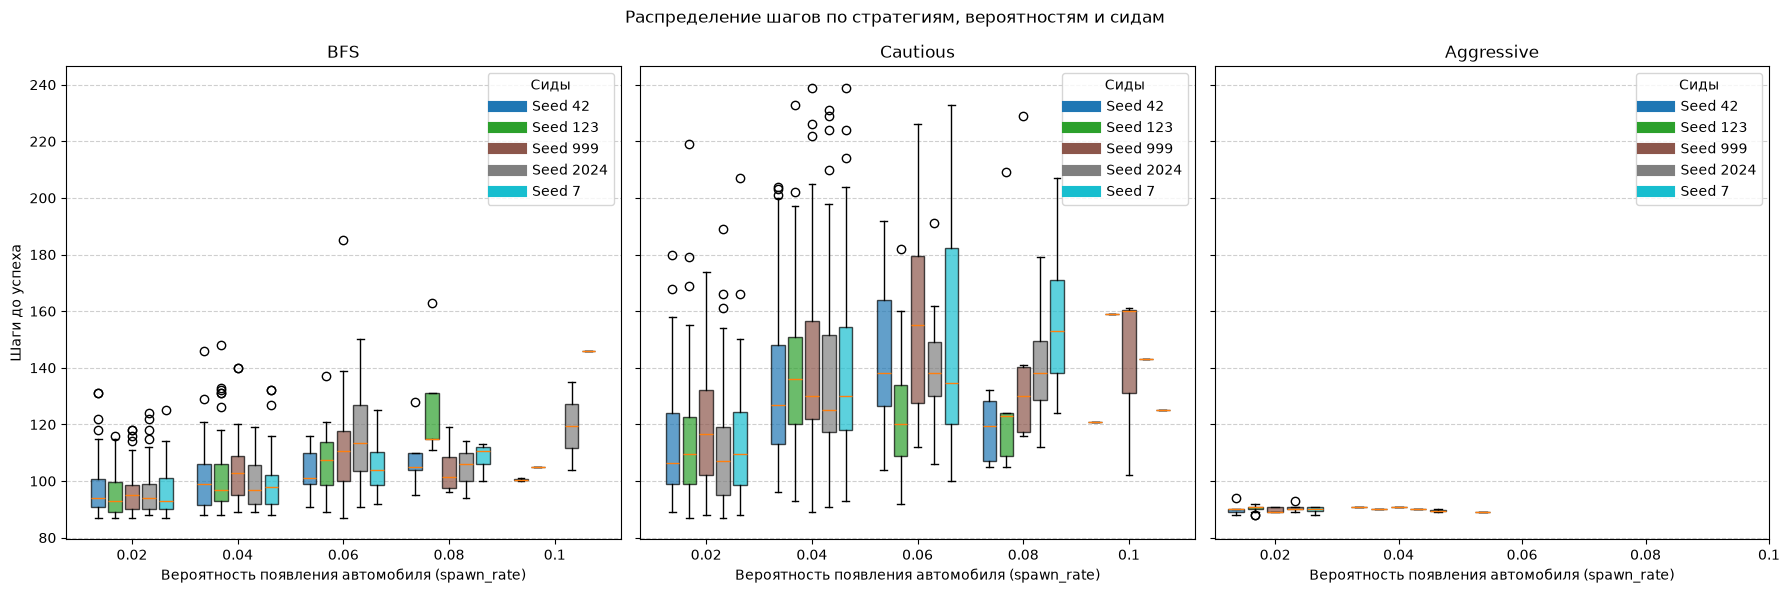

In [17]:
strategy_labels = {
    "BFS": "BFS",
    "Careful": "Cautious",
    "Aggressive": "Aggressive",
}

strategy_keys = list(strategy_labels)
probs = sorted(results[strategy_keys[0]].keys())
seed_colors = plt.cm.tab10(np.linspace(0, 1, len(seeds)))

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

group_width = 0.8
box_width = group_width / len(seeds) * 0.8
seed_offsets = np.linspace(
    -group_width / 2 + group_width / (2 * len(seeds)),
    group_width / 2 - group_width / (2 * len(seeds)),
    len(seeds),
)

for ax, strategy in zip(axes, strategy_keys):
    for seed_idx, seed in enumerate(seeds):
        for prob_idx, prob in enumerate(probs):
            distribution = results[strategy][prob][seed]["steps_distribution"]

            # Для этого сида и вероятности не было успешных эпизодов
            if not distribution:
                continue

            position = prob_idx + seed_offsets[seed_idx]
            box = ax.boxplot(
                [distribution],
                positions=[position],
                widths=box_width,
                patch_artist=True,
                manage_ticks=False,
            )
            box["boxes"][0].set_facecolor(seed_colors[seed_idx])
            box["boxes"][0].set_alpha(0.7)

        # Элемент легенды для сида
        ax.plot([], [], color=seed_colors[seed_idx], linewidth=8, label=f"Seed {seed}")

    ax.set_title(strategy_labels[strategy])
    ax.set_xlabel("Вероятность появления автомобиля (spawn_rate)")
    ax.set_xticks(range(len(probs)))
    ax.set_xticklabels([str(p) for p in probs])
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.legend(title="Сиды")

axes[0].set_ylabel("Шаги до успеха")
fig.suptitle("Распределение шагов по стратегиям, вероятностям и сидам")
plt.tight_layout()
plt.show()


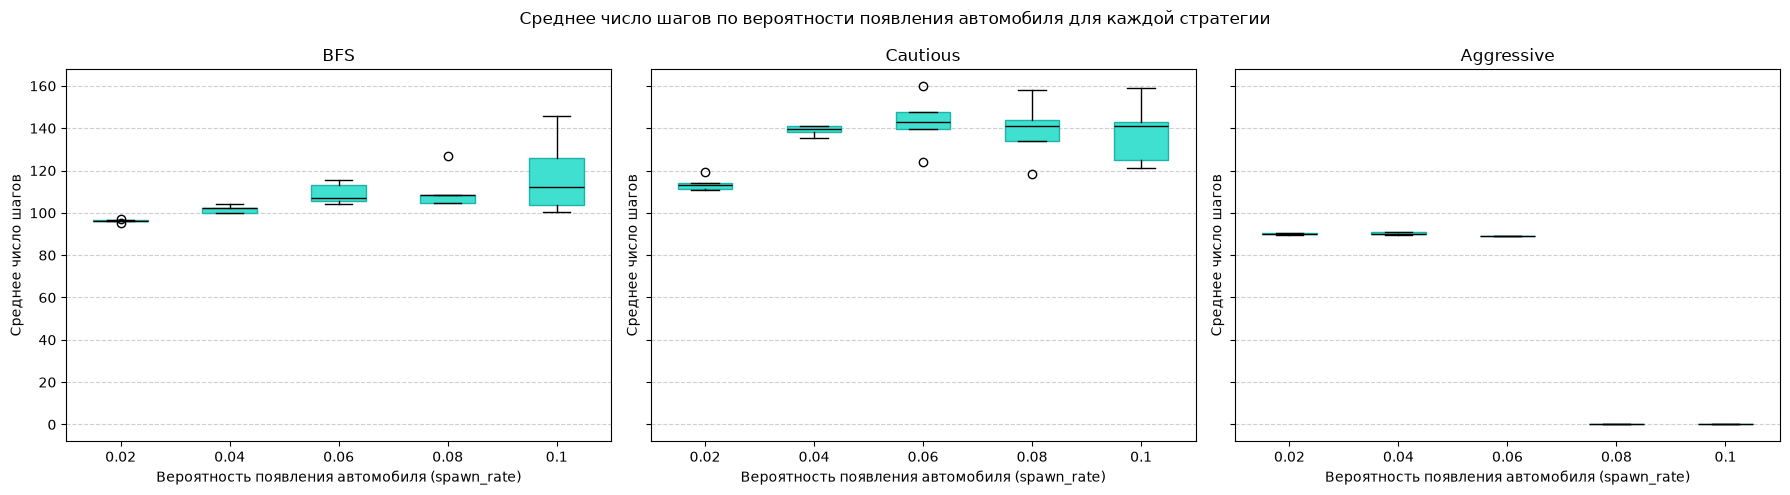

In [ ]:
plot_probs = sorted({ p for strategy in ["BFS", "Careful", "Aggressive"] for p in results.get(strategy, {}) })
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, strategy in zip(axes, ["BFS", "Careful", "Aggressive"]):
    distributions = []
    for prob in plot_probs:
        values = [
            results.get(strategy, {}).get(prob, {}).get(seed, {}).get("avg_steps", 0)
            for seed in seeds
        ]
        values = [v for v in values if v > 0]
        distributions.append(values if values else [0])
    
    bp = ax.boxplot(
        distributions,
        positions=range(len(plot_probs)),
        widths=0.5,
        patch_artist=True,
        medianprops={"color": "black"},
    )
    
    for box in bp['boxes']:
        box.set_facecolor('turquoise')      
        box.set_edgecolor('#20B2AA')       
        
    ax.set_xticks(range(len(plot_probs)))
    ax.set_xticklabels([str(p) for p in plot_probs])
    ax.set_xlabel("Вероятность появления автомобиля (spawn_rate)")
    ax.set_ylabel("Среднее число шагов")
    ax.set_title(strategy_labels.get(strategy, strategy))
    ax.grid(axis="y", linestyle="--", alpha=0.6)

fig.suptitle("Среднее число шагов по вероятности появления автомобиля для каждой стратегии")
plt.tight_layout()
plt.show()